<a href="https://colab.research.google.com/github/L66380/new-customer-discount-ab-test/blob/main/new_customer_discount_ab_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import pandas as pd
from scipy import stats

np.random.seed(42)

print("Project ready!")


Project ready!


In [2]:

# Simulate an A/B test for new customers
n = 1000

df = pd.DataFrame({
    "customer_id": range(1, n + 1),
    "group": np.random.choice(["A", "B"], size=n)
})

# A = No discount
# B = 10% discount
df["discount"] = np.where(df["group"] == "B", 10, 0)

df.head(10)


,customer_id,group,discount
0,1,A,0
1,2,B,10
2,3,A,0
3,4,A,0
4,5,A,0
5,6,B,10
6,7,A,0
7,8,A,0
8,9,A,0
9,10,B,10


In [3]:

# Simulated purchase probabilities
# A: 8% without discount
# B: 12% with discount

df["purchased"] = np.where(
    df["group"] == "A",
    np.random.binomial(1, 0.08, len(df)),
    np.random.binomial(1, 0.12, len(df))
)

df.head(10)


,customer_id,group,discount,purchased
0,1,A,0,0
1,2,B,10,0
2,3,A,0,0
3,4,A,0,0
4,5,A,0,0
5,6,B,10,0
6,7,A,0,0
7,8,A,0,0
8,9,A,0,1
9,10,B,10,0


In [4]:

results = df.groupby("group").agg(
    customers=("customer_id", "count"),
    purchases=("purchased", "sum"),
    conversion_rate=("purchased", "mean")
)

results["conversion_rate"] *= 100

print(results)


       customers  purchases  conversion_rate
group                                       
A            490         40         8.163265
B            510         53        10.392157


In [5]:

from scipy.stats import chi2_contingency

table = pd.crosstab(df["group"], df["purchased"])

chi2, p_value, dof, expected = chi2_contingency(
    table, correction=False
)

print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Statistically significant difference")
else:
    print("No statistically significant difference")


P-value: 0.2251
No statistically significant difference


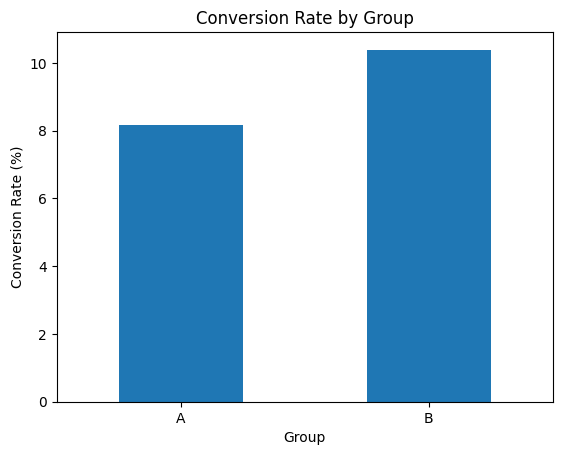

In [6]:

import matplotlib.pyplot as plt

results["conversion_rate"].plot(
    kind="bar",
    title="Conversion Rate by Group",
    ylabel="Conversion Rate (%)",
    xlabel="Group",
    rot=0
)

plt.show()


Conclusion

Group B had a higher conversion rate (10.39%) than Group A (8.16%), but the difference was not statistically significant (p = 0.2251). Further testing is recommended.